In [3]:
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import datasets as dt , layers as lr , models as md
from tensorflow.keras.applications import EfficientNetB0 as enetb0

import matplotlib.pyplot as plt

import pandas as pd

PART 1 
MINE -> CUSTOM CNN 

In [4]:

( img , lbl ) , ( tst_img , tst_lbl ) = dt.cifar10.load_data ()

ene_img = img.copy() 
ene_tst_img = tst_img.copy() 


img = img / 255.0
tst_img = tst_img / 255.0

val_img = img [ 45000: ]
val_lbl = lbl [ 45000: ]

img = img [ :45000 ]
lbl = lbl [ :45000 ]

ene_val_img = ene_img [ 45000: ]
ene_img = ene_img [ :45000 ]

pd.DataFrame ( {
    'DATASET': [ 'TRAINING' , 'VALIDATION' , 'TESTING' ] ,
    'NUM OF IMAGES': [ img.shape [ 0 ] , val_img.shape [ 0 ] , tst_img.shape [ 0 ] ] ,
    'HEIGHT': [ img.shape [ 1 ] , val_img.shape [ 1 ] , tst_img.shape [ 1 ] ] ,
    'WIDTH': [ img.shape [ 2 ] , val_img.shape [ 2 ] , tst_img.shape [ 2 ] ] ,
    'CHANNELS': [ img.shape [ 3 ] , val_img.shape [ 3 ] , tst_img.shape [ 3 ] ] }
)


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1366s 8us/step


,DATASET,NUM OF IMAGES,HEIGHT,WIDTH,CHANNELS
0,TRAINING,45000,32,32,3
1,VALIDATION,5000,32,32,3
2,TESTING,10000,32,32,3


In [5]:

input = keras.Input ( shape = ( 32 , 32 , 3 ) )


l = lr.Conv2D ( 32 , ( 3 , 3 ) , activation = 'relu' , padding = 'same' ) ( input ) # 32 X 32 X 32   --> N - F + 1 =  32 - 3 + 1 = 30 X 30 X 32 
l = lr.Conv2D ( 32 , ( 3 , 3 ) , activation = 'relu' , padding = 'same' ) ( l ) # 32 X 32 X 32
l = lr.Conv2D ( 32 , ( 3 , 3 ) , activation = 'relu' , padding = 'same' ) ( l ) # 32 X 32 X 32
l = lr.MaxPooling2D ( ( 2 , 2 ) ) ( l ) # 16 X 16 X 32


l = lr.Conv2D ( 64 , ( 3 , 3 ) , activation = 'relu' , padding = 'same' ) ( l ) # 16 x 16 x 64
l = lr.Conv2D ( 64 , ( 3 , 3 ) , activation = 'relu' , padding = 'same' ) ( l ) # 16 x 16 x 64
l = lr.MaxPooling2D ( ( 2 , 2 ) ) ( l ) # 8 x 8 x 64


l = lr.Conv2D ( 128 , ( 3 , 3 ) , activation = 'relu' , padding = 'same' ) ( l ) # 8 x 8 x 128
l = lr.MaxPooling2D ( ( 2 , 2 ) ) ( l ) # 4 x 4 x 128


l = lr.Flatten () ( l ) # 2048
l = lr.Dense ( 128 , activation = 'relu' ) ( l )
l = lr.Dense ( 10 , activation = 'softmax' ) ( l ) 

mdl = md.Model ( input ,  l )

mdl.summary ()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 412,234 (1.57 MB)

 Trainable params: 412,234 (1.57 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:

mdl.compile (
    optimizer = 'adam' ,
    loss = 'sparse_categorical_crossentropy' ,
    metrics = [ 'accuracy' ]
  )

history = mdl.fit ( img , lbl , epochs = 15 , validation_data = ( val_img , val_lbl ) )

Epoch 1/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 25s 11ms/step - accuracy: 0.4480 - loss: 1.5118 - val_accuracy: 0.5992 - val_loss: 1.1277
Epoch 2/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.6465 - loss: 0.9958 - val_accuracy: 0.7038 - val_loss: 0.8599
Epoch 3/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.7258 - loss: 0.7832 - val_accuracy: 0.7228 - val_loss: 0.7958
Epoch 4/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.7678 - loss: 0.6677 - val_accuracy: 0.7454 - val_loss: 0.7370
Epoch 5/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8032 - loss: 0.5588 - val_accuracy: 0.7520 - val_loss: 0.7386
Epoch 6/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8327 - loss: 0.4734 - val_accuracy: 0.7696 - val_loss: 0.7016
Epoch 7/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8576 - loss: 0.3975 - val_accuracy: 0.7662 - val_loss: 0.7826
Epoch 8/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8832 - loss: 0.3298 

In [7]:

res = mdl.evaluate ( tst_img , tst_lbl )

print ( "TEST ACCURACY PERCENTAGE : " + str ( res [ 1 ] * 100 ) + " % " )
print ( "TEST LOSS : " + str ( res [ 0 ] ) )

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7485 - loss: 1.2693
TEST ACCURACY PERCENTAGE : 74.84999895095825 % 
TEST LOSS : 1.2692992687225342


PART 2
BUILTIN MODEL -> EFFICIENTNETB0

In [8]:

trmdl = enetb0 (
    include_top = False ,
    weights = 'imagenet' ,
    input_shape = ( 224 , 224 , 3 )
)

trmdl.trainable = False

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [14]:
input2 = keras.Input ( shape = ( 32 , 32 , 3 ) )

ll = lr.Resizing ( 224 , 224 ) ( input2 ) # cause enetb0 need img w 244 x 244 sz 
ll = trmdl ( ll , training = False )

ll = lr.GlobalAveragePooling2D () ( ll )
ll = lr.Dense ( 128 , activation = 'relu' ) ( ll ) 


ll = lr.Dense ( 10 , activation = 'softmax' ) ( ll )

enemdl = md.Model ( input2 , ll )


In [10]:

enemdl.compile (
    optimizer = 'adam' ,
    loss = 'sparse_categorical_crossentropy' ,
    metrics = [ 'accuracy' ]
  )

enehistory = enemdl.fit ( img , lbl , epochs = 15 , validation_data = ( ene_val_img , val_lbl ) )

Epoch 1/15


E0000 00:00:1795462529.215948     154 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795462529.381262     154 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795462531.330752     154 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795462531.509966     154 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1405/1407 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.1004 - loss: 2.3088

E0000 00:00:1795462583.967875     153 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795462584.133624     153 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795462585.387216     153 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795462585.564130     153 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1407/1407 ━━━━━━━━━━━━━━━━━━━━ 93s 48ms/step - accuracy: 0.0995 - loss: 2.3042 - val_accuracy: 0.1184 - val_loss: 2.5313
Epoch 2/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 45s 32ms/step - accuracy: 0.0994 - loss: 2.3028 - val_accuracy: 0.1150 - val_loss: 2.5498
Epoch 3/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 44s 31ms/step - accuracy: 0.0989 - loss: 2.3027 - val_accuracy: 0.1158 - val_loss: 2.5437
Epoch 4/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 44s 32ms/step - accuracy: 0.1005 - loss: 2.3028 - val_accuracy: 0.1154 - val_loss: 2.5449
Epoch 5/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 44s 31ms/step - accuracy: 0.0990 - loss: 2.3028 - val_accuracy: 0.1158 - val_loss: 2.5484
Epoch 6/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 44s 31ms/step - accuracy: 0.0993 - loss: 2.3027 - val_accuracy: 0.1164 - val_loss: 2.5486
Epoch 7/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 44s 32ms/step - accuracy: 0.0998 - loss: 2.3028 - val_accuracy: 0.1158 - val_loss: 2.5426
Epoch 8/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 44s 31ms/step - accuracy: 0.0991 - loss: 2.30

In [11]:
eneres = enemdl.evaluate ( ene_tst_img , tst_lbl )

print ( "EFFICIENTNET TEST ACCURACY PERCENTAGE : " + str ( eneres [ 1 ] * 100 ) + " % " )
print ( "EFFICIENTNET TEST LOSS : " + str ( eneres [ 0 ] ) )

311/313 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.1181 - loss: 2.5697

E0000 00:00:1795463241.245829     156 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795463241.407092     156 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795463241.666756     156 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795463241.863130     156 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


313/313 ━━━━━━━━━━━━━━━━━━━━ 16s 52ms/step - accuracy: 0.1204 - loss: 2.5588
EFFICIENTNET TEST ACCURACY PERCENTAGE : 12.039999663829803 % 
EFFICIENTNET TEST LOSS : 2.55875301361084


PART 3 
CMP -> COMPARISON

            MODEL  TEST ACCURACY  TEST LOSS
0             CNN         0.7485   1.269299
1  EfficientNetB0         0.1204   2.558753




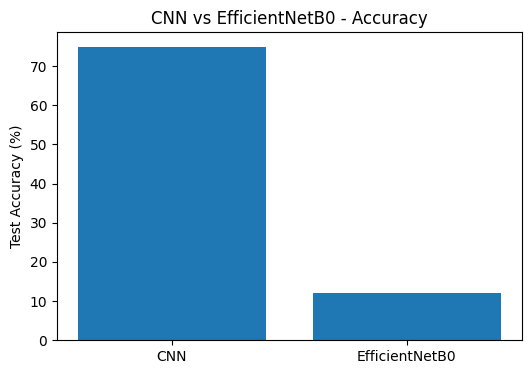

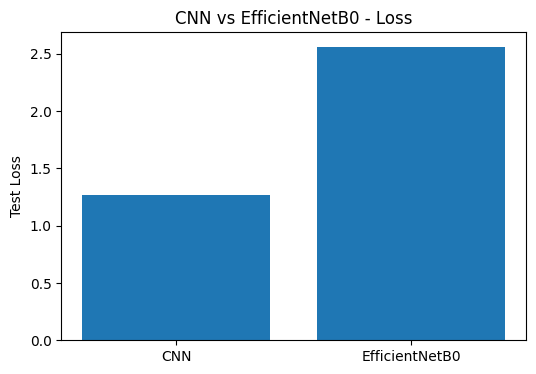

In [12]:
comparison = pd.DataFrame ( {
    'MODEL': [ 'CNN' , 'EfficientNetB0' ] ,
    'TEST ACCURACY': [
        res [ 1 ] ,
        eneres [ 1 ]
    ] ,
    'TEST LOSS': [
        res [ 0 ] ,
        eneres [ 0 ]
    ]
} )

print ( comparison )


print () 
print () 

plt.figure ( figsize = ( 6 , 4 ) )

plt.bar (
    [ 'CNN' , 'EfficientNetB0' ] ,
    [ res [ 1 ] * 100 , eneres [ 1 ] * 100 ]
)

plt.ylabel ( 'Test Accuracy (%)' )
plt.title ( 'CNN vs EfficientNetB0 - Accuracy' )

plt.show ()

print () 
print () 


plt.figure ( figsize = ( 6 , 4 ) )

plt.bar (
    [ 'CNN' , 'EfficientNetB0' ] ,
    [ res [ 0 ] , eneres [ 0 ] ]
)

plt.ylabel ( 'Test Loss' )
plt.title ( 'CNN vs EfficientNetB0 - Loss' )

plt.show ()